
# Flight Delay Prediction — Iteration 1: Random Forest

## 1. Introduction

In Iteration 0, I used k-NN to predict whether a flight would be delayed by 15 minutes or more.

For Iteration 1, I decided to use Random Forest to explore a different classification algorithm.

Following feedback from my teacher, Martijn, I changed the chronological train-test split to a random 80/20 split.

I will first train a baseline Random Forest model and then investigate whether class balancing improves the prediction of delayed flights.


## 2. Loading the Prepared Data

The data was cleaned and preprocessed in my Data Preparation notebook.

I am using the updated Version 2 dataset, where I changed the chronological train/test split to a random split based on previous feedback from Martijn.

The dataset contains 699 features, including numerical features and one-hot encoded categorical features.

I will also load the feature names saved during Data Preparation. This will help me identify which features are important when investigating the model's performance later.

In [8]:
from scipy.sparse import load_npz
import numpy as np

X_train = load_npz("prepared_data/X_train_final_v2.npz")
X_test = load_npz("prepared_data/X_test_final_v2.npz")
y_train = np.load("prepared_data/y_train_final_v2.npy")
y_test = np.load("prepared_data/y_test_final_v2.npy")

feature_names = np.load(
    "prepared_data/feature_names_v2.npy",
    allow_pickle=True
)

print("Number of features:", len(feature_names))
print("Features match:", len(feature_names) == X_train.shape[1])
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

Number of features: 699
Features match: True
(418748, 699) (418748,) (104687, 699) (104687,)



## 3. Random Forest Baseline

In this step, I will train a Random Forest classifier to predict whether a flight will be delayed by 15 minutes or more.

Random Forest combines multiple decision trees to make predictions. Each tree learns patterns from the training data and the final prediction is based on the votes of the trees.

I will first train the model without class balancing to establish a baseline. Afterwards, I will compare it with a model that gives more importance to delayed flights.


In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

rf_baseline.fit(X_train, y_train)


RandomForestClassifier(n_jobs=-1, random_state=42)


## 4. Model Predictions and Evaluation

After training the baseline Random Forest model, I will use the testing dataset to evaluate its performance.

I will compare the predicted flight delays with the actual values and examine how well the model identifies delayed flights.

Since delayed flights represent only around 18% of the dataset, accuracy alone may not give a complete picture of the model's performance.


In [10]:
y_pred_baseline = rf_baseline.predict(X_test)

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_baseline))
print(confusion_matrix(y_test, y_pred_baseline))

              precision    recall  f1-score   support

         0.0       0.84      0.96      0.89     85601
         1.0       0.46      0.15      0.23     19086

    accuracy                           0.81    104687
   macro avg       0.65      0.56      0.56    104687
weighted avg       0.77      0.81      0.77    104687

[[82088  3513]
 [16148  2938]]



### 4.1 Baseline Results

The baseline Random Forest achieved an accuracy of approximately 81%. However, the results show that the model performs much better at identifying on-time flights than delayed flights.

For delayed flights (class 1), precision was 0.46, recall was 0.15 and the F1-score was 0.23.

According to the confusion matrix, the model correctly identified 2,938 delayed flights but missed 16,148.

Since only around 18% of flights are delayed, the model appears to favour the majority class. This shows why accuracy alone is not enough to evaluate its performance.



### 4.2 Confusion Matrix

To better understand the model's performance, I visualised the confusion matrix as a heatmap.

This helps me identify how many flights were correctly classified and where the model made mistakes, especially when predicting delayed flights.


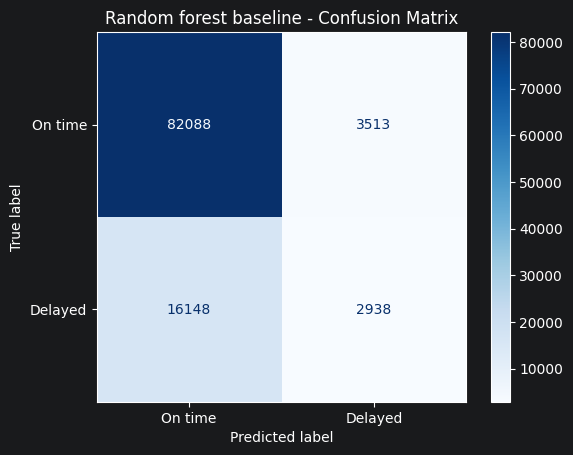

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_baseline, display_labels=["On time", "Delayed"], cmap="Blues", values_format="d")

plt.title("Random forest baseline - Confusion Matrix")
plt.show()


## 5. Random Forest with Class Balancing

The baseline Random Forest achieved an accuracy of 81%, but only identified 15% of delayed flights.

Since delayed flights represent approximately 18% of the dataset, I decided to investigate class balancing.

I will train a second Random Forest using `class_weight="balanced"`, which gives more weight to the minority class during training.

I will use the same training and testing datasets to compare both models fairly.


In [13]:
rf_balanced = RandomForestClassifier (
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",
)

rf_balanced.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

In [14]:
y_pred_balanced = rf_balanced.predict(X_test)

print(classification_report(y_test, y_pred_balanced))
print(confusion_matrix(y_test, y_pred_balanced))

              precision    recall  f1-score   support

         0.0       0.83      0.96      0.89     85601
         1.0       0.46      0.15      0.22     19086

    accuracy                           0.81    104687
   macro avg       0.65      0.55      0.56    104687
weighted avg       0.77      0.81      0.77    104687

[[82306  3295]
 [16290  2796]]


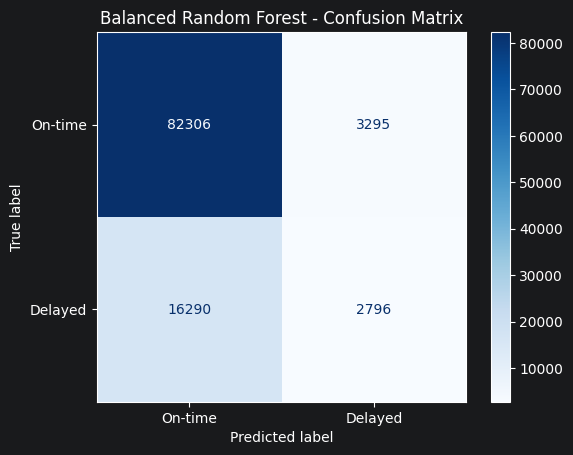

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced,
    display_labels=["On-time", "Delayed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Balanced Random Forest - Confusion Matrix")
plt.show()


### 5.1 Comparison of Baseline and Balanced Random Forest

After training the Random Forest with `class_weight="balanced"`, I compared its results with the baseline model.

The baseline model achieved a recall of 0.15 and an F1-score of 0.23 for delayed flights. The balanced model also achieved a recall of approximately 0.15, but its F1-score decreased slightly to 0.22.

The confusion matrix showed that the balanced model correctly identified 2,796 delayed flights, compared to 2,938 with the baseline model.

This means that class balancing did not improve the prediction of delayed flights in this experiment.

I learned that class balancing does not automatically improve model performance. It is important to evaluate different approaches rather than assuming they will produce better results.



## 6. Model Comparison

In this section, I compare the baseline Random Forest with the balanced Random Forest.

Both models were trained and tested using the same dataset. The only difference is that the second model uses `class_weight="balanced"`.

I will compare precision, recall and F1-score for delayed flights (class 1) to investigate whether class balancing improved the model's performance.


In [16]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Baseline RF", "Balanced RF"],
    "Precision": [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_balanced)
    ],
    "Recall": [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_balanced)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_balanced)
    ]
})

comparison.round(3)

,Model,Precision,Recall,F1-score
0,Baseline RF,0.455,0.154,0.230
1,Balanced RF,0.459,0.146,0.222



### 6.1 Visual Comparison

To make the results easier to interpret, I created a bar chart comparing precision, recall and F1-score for delayed flights.

This allows me to see whether class balancing improved the model's ability to identify delays.


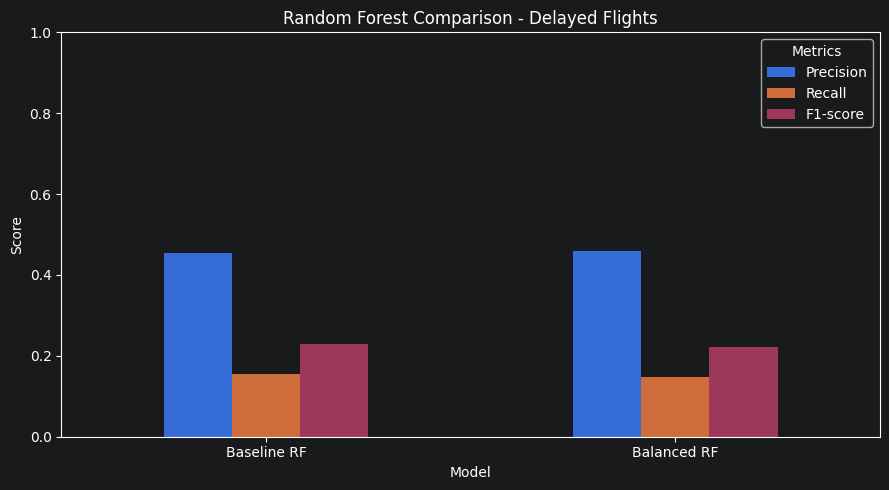

In [17]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Random Forest Comparison - Delayed Flights")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()


### 6.2 Conclusion

The comparison shows that class balancing did not improve the prediction of delayed flights.

The baseline Random Forest achieved a slightly higher recall (0.154) and F1-score (0.230), while the balanced Random Forest achieved a slightly higher precision (0.459).

Both models correctly identified only around 15% of delayed flights. This suggests that the models still struggle to distinguish delayed flights from on-time flights.

Based on these results, I would keep the baseline Random Forest for now. In future experiments, I could investigate additional features or different prediction thresholds to improve recall.



## 7. Final Conclusion and Reflection

I explored Random Forest as an alternative to the k-NN model from Iteration 0.

Following feedback from Martijn, I used a random train-test split and experimented with class balancing.

The baseline Random Forest achieved an accuracy of approximately 81%, but its recall for delayed flights was only 15%. Using `class_weight="balanced"` did not improve the results.

This experiment helped me understand that a high accuracy does not necessarily mean a model performs well, especially when the dataset contains imbalanced classes.

I also learned that class balancing does not guarantee better predictions. Comparing precision, recall, F1-score and confusion matrices helped me understand the strengths and weaknesses of both models.

For future improvements, I would investigate additional features and different prediction thresholds to improve the detection of delayed flights.


## 8. Random Forest with Random Undersampling

During another feedback session with Martijn, I realised that my previous approach using `class_weight="balanced"` did not actually change the number of samples in each class. Instead, it gave more importance to delayed flights during training.

This time, I will use Random Undersampling to balance the training dataset. This method randomly removes samples from the majority class (on-time flights) until both classes have the same number of samples.

Before applying undersampling, I will first check how many flights belong to each class.

I will only balance the training data and keep the test data unchanged so that I can evaluate the model on the original flight delay distribution.

In [18]:

# checking the class distribution before balancing
import pandas as pd

class_distribution = pd.Series(y_train).value_counts().sort_index()

print("Class distribution before balancing:")
print("On-time flights (0):", class_distribution[0])
print("Delayed flights (1):", class_distribution[1])

print("\nClass percentages:")
print((class_distribution / class_distribution.sum() * 100).round(2))


Class distribution before balancing:
On-time flights (0): 342402
Delayed flights (1): 76346

Class percentages:
0.0    81.77
1.0    18.23
Name: count, dtype: float64


### 9. Balancing the Training Dataset

The training dataset contains 342,402 on-time flights (81.77%) and 76,346 delayed flights (18.23%). This means the model has considerably more examples of on-time flights, which could make it harder to recognise delayed flights.

To address this, I will apply Random Undersampling. This method randomly removes on-time flights until both classes contain the same number of samples.

I will only apply this to the training dataset. The test dataset will remain unchanged to evaluate how well the model performs on the original distribution of flights.

In [19]:

from imblearn.under_sampling import RandomUnderSampler
import pandas as pd

# applying random undersampling to training data only
rus = RandomUnderSampler(random_state=42)

X_train_balanced, y_train_balanced = rus.fit_resample(
    X_train, y_train
)

# checking class distribution after balancing
balanced_distribution = pd.Series(y_train_balanced).value_counts().sort_index()

print("Class distribution after balancing:")
print("On-time flights (0):", balanced_distribution[0])
print("Delayed flights (1):", balanced_distribution[1])

print("\nBalanced training dataset shape:")
print(X_train_balanced.shape)


Class distribution after balancing:
On-time flights (0): 76346
Delayed flights (1): 76346

Balanced training dataset shape:
(152692, 699)


/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


### 10. Training Random Forest on the Balanced Dataset

Now that both classes contain the same number of flights, I will train Random Forest again using the balanced training dataset.

I will use the same Random Forest settings as before, without `class_weight="balanced"`, because the training dataset is already balanced.

After training, I will evaluate the model using the test dataset. I want to see whether balancing improves the model's ability to recognise delayed flights, particularly its recall and F1-score.

I will also compare the results with my previous Random Forest models to understand whether balancing the dataset actually improves performance.

Random Forest with Random Undersampling
---------------------------------------
Accuracy: 0.631
Precision: 0.2787
Recall: 0.6449
F1-score: 0.3892

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.63      0.74     85601
         1.0       0.28      0.64      0.39     19086

    accuracy                           0.63    104687
   macro avg       0.58      0.64      0.56    104687
weighted avg       0.78      0.63      0.67    104687



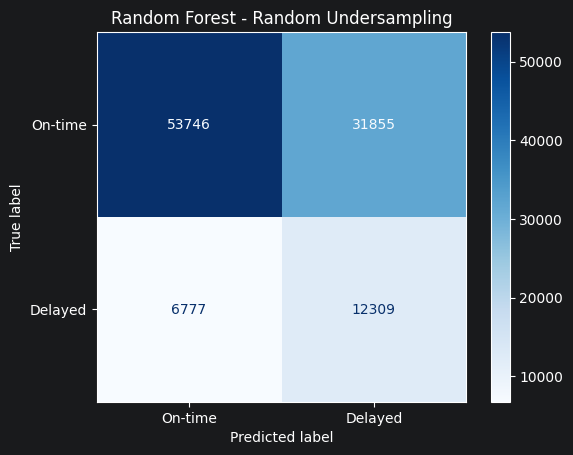

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# training Random Forest on balanced training data
rf_undersampled = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_undersampled.fit(X_train_balanced, y_train_balanced)

# predicting on the original, unchanged test dataset
y_pred_undersampled = rf_undersampled.predict(X_test)

# evaluating model performance
print("Random Forest with Random Undersampling")
print("---------------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_undersampled), 4))
print("Precision:", round(precision_score(y_test, y_pred_undersampled), 4))
print("Recall:", round(recall_score(y_test, y_pred_undersampled), 4))
print("F1-score:", round(f1_score(y_test, y_pred_undersampled), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_undersampled))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_undersampled,
    display_labels=["On-time", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest - Random Undersampling")
plt.show()


### 11. Results and Reflection

After applying Random Undersampling, I trained Random Forest again using the balanced training dataset. The model achieved an accuracy of approximately 63%, a recall of 64.49%, and an F1-score of 38.92% for delayed flights.

Looking at the confusion matrix, the model correctly identified 12,309 delayed flights but missed 6,777. However, it also incorrectly predicted that 31,855 on-time flights would be delayed.

This shows that the model can recognise a considerable number of delayed flights, but it also produces many false predictions. The precision for delayed flights was only 28%, meaning that most flights predicted as delayed were actually on time.

Although I successfully balanced the training dataset, this does not necessarily mean the model performs better overall. I still need to compare these results with my previous Random Forest models to understand whether undersampling improved the performance.


### 12. Comparison of Random Forest Models

After testing three different Random Forest approaches, I compared their performance to understand whether balancing the dataset improved the predictions.

The baseline Random Forest achieved approximately 81% accuracy, but only identified 15.39% of delayed flights. Using `class_weight="balanced"` did not improve the results, as the recall decreased slightly to 14.65%.

Random Undersampling produced different results. The recall increased to 64.49%, meaning the model correctly identified 12,309 delayed flights compared to only 2,938 with the baseline model. The F1-score also improved from approximately 23% to 39%.

However, the accuracy decreased to 63.10%, and the model incorrectly predicted 31,855 on-time flights as delayed. This shows that although undersampling helped the model recognise more delayed flights, it also increased the number of false predictions.

From this experiment, I learned that balancing the dataset does not automatically make a model better. It depends on which evaluation metrics are most important. In my case, I want the model to recognise delayed flights without producing too many incorrect delay predictions.

For my next step, I will follow Martijn's recommendation and investigate the 699 features using a correlation heatmap and feature importance analysis. I will then experiment with reducing the number of features to see whether this improves the model's performance.

## 13. Feature Analysis and Selection

During my feedback session with Martijn, we discussed whether having 699 features could affect the performance of my Random Forest model.

Martijn suggested creating a correlation heatmap to investigate the relationships between the features and the target variable (`DEP_DEL15`). This could help me identify which features might be useful for predicting flight delays.

Before removing any features, I will create a copy of my V2 dataset so that the original data remains unchanged. I will then investigate the feature correlations and use the results to decide which features to examine further.

I will use the original V2 training dataset for this analysis, rather than the undersampled dataset, so I can investigate the relationships using all available training examples.

In [21]:

# creating copies of the original V2 datasets
X_train_features = X_train.copy()
X_test_features = X_test.copy()

# copy the feature names
feature_names_features = feature_names.copy()

# checking the dataset shapes
print("Original training:", X_train.shape)
print("Copied training:", X_train_features.shape)

print("Original testing:", X_test.shape)
print("Copied testing:", X_test_features.shape)

print("Number of features:", len(feature_names_features))


Original training: (418748, 699)
Copied training: (418748, 699)
Original testing: (104687, 699)
Copied testing: (104687, 699)
Number of features: 699


### 14. Correlation Heatmap — Numerical Features

I will first create a correlation heatmap using the eight numerical features and the target variable, `DEP_DEL15`.

The heatmap will show the strength and direction of the linear relationships between these variables. I want to investigate whether any numerical features have a stronger relationship with flight delays and whether some features are highly correlated with each other.

A low correlation does not automatically mean that a feature is useless, because Random Forest can also learn nonlinear relationships. Therefore, I will use this analysis as a starting point rather than immediately removing features.

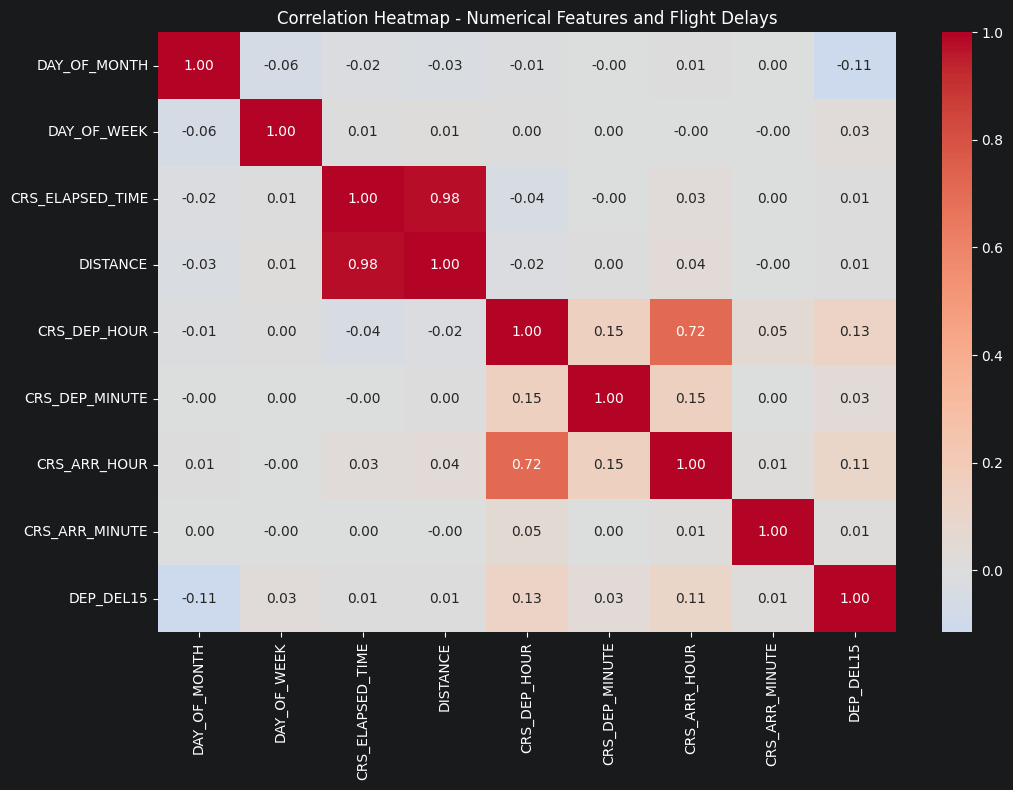

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# selecting the eight numerical features
numerical_features = [
    "DAY_OF_MONTH",
    "DAY_OF_WEEK",
    "CRS_ELAPSED_TIME",
    "DISTANCE",
    "CRS_DEP_HOUR",
    "CRS_DEP_MINUTE",
    "CRS_ARR_HOUR",
    "CRS_ARR_MINUTE"
]

# finding their positions in the encoded dataset
numerical_indices = [
    list(feature_names_features).index(name)
    for name in numerical_features
]

# extracting numerical features from training data
X_numerical = X_train_features[:, numerical_indices].toarray()

# creating DataFrame
df_numerical = pd.DataFrame(
    X_numerical,
    columns=numerical_features
)

# adding target variable
df_numerical["DEP_DEL15"] = y_train

# calculating correlations
correlation_matrix = df_numerical.corr()

# creating heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap - Numerical Features and Flight Delays")
plt.tight_layout()
plt.show()


### 15. Interpretation of the Correlation Heatmap

After creating the correlation heatmap, I noticed that most numerical features have a weak linear relationship with flight delays.

The strongest positive correlation with `DEP_DEL15` is `CRS_DEP_HOUR` (0.13), followed by `CRS_ARR_HOUR` (0.11). This suggests that flights scheduled later in the day may be slightly more likely to experience delays.

`DAY_OF_MONTH` has a negative correlation of -0.11, suggesting that flights later in the month were slightly less likely to be delayed.

I also noticed that `CRS_ELAPSED_TIME` and `DISTANCE` have a very strong correlation of 0.98. This makes sense because longer flights generally cover greater distances. These features may contain overlapping information.

Although several features have correlations close to zero with the target variable, I cannot conclude that they are useless. Random Forest can identify more complex relationships that are not visible through linear correlation.

For this reason, I will not remove any features yet. I will first investigate the categorical features and use Random Forest feature importance to better understand which features contribute to the predictions.

### 16. Correlation Analysis of All Features

After investigating the numerical features, I will now look at all 699 features, including the categorical features that were transformed using One-Hot Encoding.

Instead of creating a heatmap with all 699 features, I will identify the 20 features with the strongest correlations with `DEP_DEL15`.

This will help me investigate whether certain airlines, airports, or departure time blocks are more strongly associated with flight delays.

I will use the training dataset only and keep the original V2 dataset unchanged. I will not remove any features based on correlation alone, because a weak linear relationship does not necessarily mean a feature is not useful for Random Forest.

               Feature  Correlation
          CRS_DEP_HOUR     0.126581
          DAY_OF_MONTH    -0.114706
          CRS_ARR_HOUR     0.106459
DEP_TIME_BLK_0600-0659    -0.070400
DEP_TIME_BLK_0700-0759    -0.058196
DEP_TIME_BLK_0800-0859    -0.046538
DEP_TIME_BLK_0001-0559    -0.038223
DEP_TIME_BLK_2000-2059     0.036703
  OP_UNIQUE_CARRIER_YX    -0.035930
DEP_TIME_BLK_1900-1959     0.035892
        CRS_DEP_MINUTE     0.033995
           DAY_OF_WEEK     0.032279
DEP_TIME_BLK_1800-1859     0.031877
            ORIGIN_DEN     0.029597
            ORIGIN_DFW     0.029155
DEP_TIME_BLK_1700-1759     0.028138
DEP_TIME_BLK_1500-1559     0.027066
DEP_TIME_BLK_2100-2159     0.026431
DEP_TIME_BLK_1600-1659     0.025839
DEP_TIME_BLK_0900-0959    -0.024249


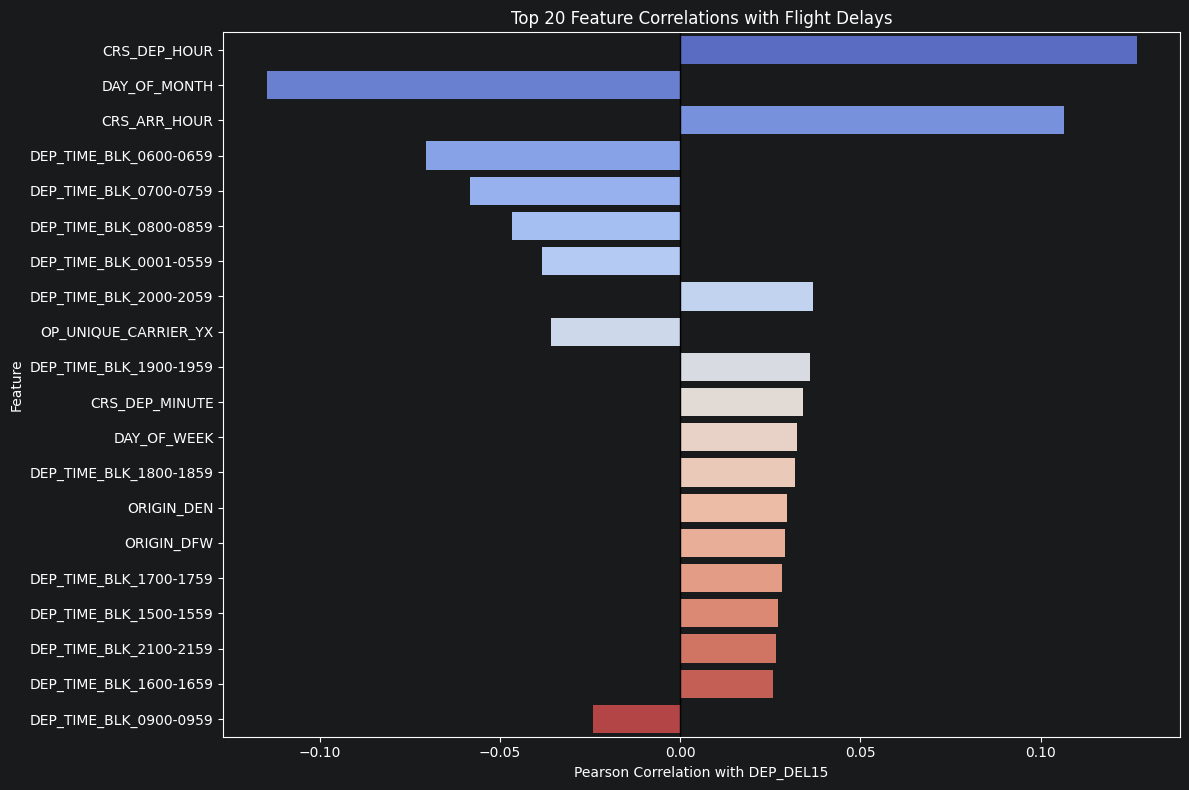

In [23]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# calculating correlations using training data only
X = X_train_features
y = np.asarray(y_train).ravel()

# calculating feature means and standard deviations
feature_means = np.asarray(X.mean(axis=0)).ravel()
feature_means_squared = np.asarray(X.power(2).mean(axis=0)).ravel()

feature_std = np.sqrt(
    np.maximum(feature_means_squared - feature_means**2, 0)
)

# calculating correlation between each feature and DEP_DEL15
y_mean = y.mean()
y_std = y.std()

xy_mean = np.asarray(X.T @ y).ravel() / len(y)

correlations = np.divide(
    xy_mean - feature_means * y_mean,
    feature_std * y_std,
    out=np.zeros(X.shape[1]),
    where=(feature_std > 0) & (y_std > 0)
)

# creating a DataFrame with feature names and correlations
correlation_df = pd.DataFrame({
    "Feature": feature_names_features,
    "Correlation": correlations
})

# selecting the 20 strongest absolute correlations
top_20 = (
    correlation_df
    .assign(Absolute_Correlation=lambda df: df["Correlation"].abs())
    .sort_values("Absolute_Correlation", ascending=False)
    .head(20)
)

print(top_20[["Feature", "Correlation"]].to_string(index=False))

# visualising the top 20 correlations
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20,
    x="Correlation",
    y="Feature",
    hue="Feature",
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Top 20 Feature Correlations with Flight Delays")
plt.xlabel("Pearson Correlation with DEP_DEL15")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### 17.Interpretation of All Feature Correlations

After calculating the correlations for all 699 features, I selected the 20 features with the strongest relationships with `DEP_DEL15`.

I noticed that departure time appears several times in the results. `CRS_DEP_HOUR` has the strongest positive correlation (0.1266), while early morning departure blocks, such as 06:00–06:59, have negative correlations. This suggests that flights scheduled earlier in the day are generally less likely to be delayed than flights scheduled later.

`DAY_OF_MONTH` has the second strongest correlation (-0.1147), suggesting that flights later in January were slightly less likely to experience delays.

Some airports and airlines also appeared in the top 20, such as `ORIGIN_DEN`, `ORIGIN_DFW`, and `OP_UNIQUE_CARRIER_YX`. However, their correlations were relatively weak.

Overall, the correlations suggest that departure time may be more relevant than individual airport or airline indicators. However, correlation only shows linear relationships and does not tell me how much a feature contributes to the Random Forest predictions.

For this reason, I will investigate feature importance before deciding which features to remove.

### 18.  Random Forest Feature Importance

After investigating the correlations, I will now use Random Forest feature importance to understand which features contribute most to the model's predictions.

Unlike correlation, Random Forest can learn more complex relationships between features and the target variable.

I will use my previously trained baseline Random Forest model to calculate feature importance. This will help me identify which features the model relies on most and which features might be less useful.

I will not remove features immediately, because low importance does not necessarily mean that a feature is unnecessary. Instead, I will use these results to guide further experiments.

             Feature  Importance
        DAY_OF_MONTH    0.263732
         DAY_OF_WEEK    0.138253
    CRS_ELAPSED_TIME    0.056944
      CRS_ARR_MINUTE    0.055828
      CRS_DEP_MINUTE    0.051497
            DISTANCE    0.051406
        CRS_ARR_HOUR    0.032645
        CRS_DEP_HOUR    0.020958
OP_UNIQUE_CARRIER_WN    0.005058
OP_UNIQUE_CARRIER_DL    0.004795
OP_UNIQUE_CARRIER_AA    0.004723
OP_UNIQUE_CARRIER_OO    0.003588
OP_UNIQUE_CARRIER_UA    0.003576
            DEST_DEN    0.003402
          ORIGIN_DEN    0.003244
          ORIGIN_ORD    0.003127
            DEST_LAS    0.002992
            DEST_DFW    0.002931
            DEST_ATL    0.002873
            DEST_ORD    0.002844


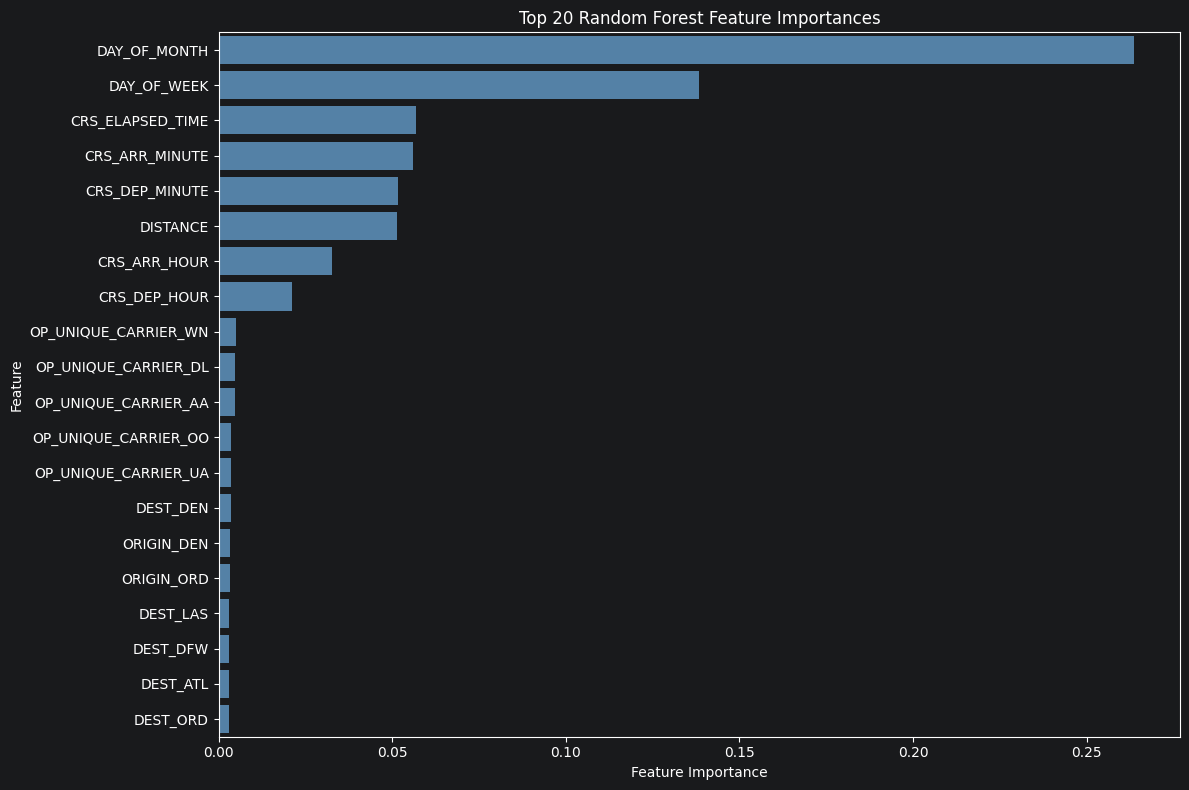

In [24]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# getting feature importance from the baseline Random Forest
importances = rf_baseline.feature_importances_

# creating a DataFrame with feature names and importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names_features,
    "Importance": importances
})

# selecting the 20 most important features
top_20_importance = importance_df.sort_values(
    "Importance", ascending=False
).head(20)

print(top_20_importance.to_string(index=False))

# visualising feature importance
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 20 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


### 19. Interpretation of Random Forest Feature Importance

After analysing the Random Forest feature importance, I noticed that the numerical features have much higher importance scores than the individual one-hot encoded features.

`DAY_OF_MONTH` is the most important feature (0.2637), followed by `DAY_OF_WEEK` (0.1383). This was interesting because both features showed relatively weak correlations with flight delays in my earlier analysis.

This shows that correlation and Random Forest feature importance measure different things. A feature can have a weak linear relationship with the target but still be useful to the model when combined with other features.

I also noticed that scheduled flight duration, distance and departure and arrival times contribute to the predictions.

The individual airline and airport features have much lower importance scores. However, because One-Hot Encoding created hundreds of separate features, their importance is spread across many columns.

Based on these results, I cannot conclude that the categorical features are unnecessary. I will investigate their importance further before selecting features to remove.

For the next experiment, I want to reduce the number of features and compare the new model with my previous Random Forest results, while keeping the original V2 dataset unchanged.

### 20. Feature Importance by Group

Because One-Hot Encoding created many separate features for airlines, airports and departure time blocks, their individual importance scores are relatively small.

To better understand their contribution, I will combine the importance scores of features that originally belonged to the same variable.

This will allow me to compare the overall importance of numerical features with categorical feature groups before deciding which features to investigate removing.

Group
DAY_OF_MONTH            0.263732
DAY_OF_WEEK             0.138253
Destination Airport     0.131013
Departure Airport       0.122189
CRS_ELAPSED_TIME        0.056944
CRS_ARR_MINUTE          0.055828
CRS_DEP_MINUTE          0.051497
DISTANCE                0.051406
Airline                 0.038093
Departure Time Block    0.037441
CRS_ARR_HOUR            0.032645
CRS_DEP_HOUR            0.020958
Name: Importance, dtype: float64


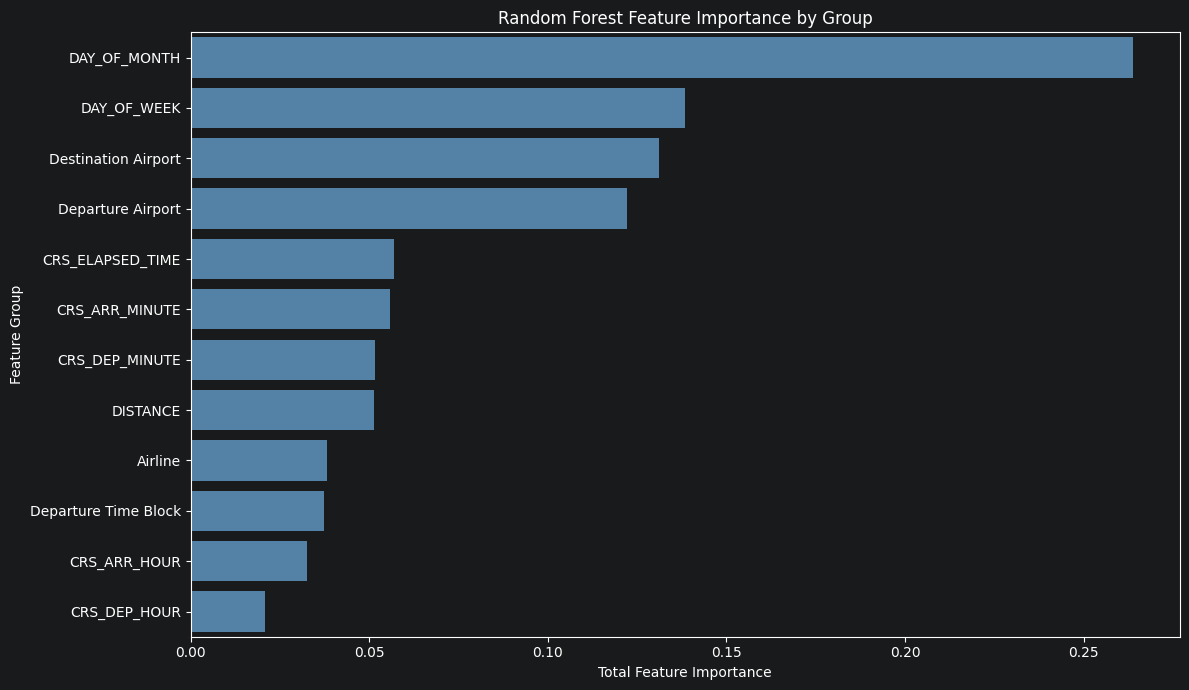

In [25]:

# creating a copy of the feature importance results
group_importance = importance_df.copy()

def get_feature_group(name):
    name = str(name)

    if name.startswith("OP_UNIQUE_CARRIER_"):
        return "Airline"
    elif name.startswith("ORIGIN_"):
        return "Departure Airport"
    elif name.startswith("DEST_"):
        return "Destination Airport"
    elif name.startswith("DEP_TIME_BLK_"):
        return "Departure Time Block"
    else:
        return name

# assigning each feature to its original group
group_importance["Group"] = group_importance["Feature"].apply(
    get_feature_group
)

# sum the importance scores within each group
group_summary = (
    group_importance.groupby("Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

print(group_summary)

# visualise the grouped importance
plt.figure(figsize=(12, 7))

sns.barplot(
    x=group_summary.values,
    y=group_summary.index,
    color="steelblue"
)

plt.title("Random Forest Feature Importance by Group")
plt.xlabel("Total Feature Importance")
plt.ylabel("Feature Group")
plt.tight_layout()
plt.show()


### 21. Interpretation of Grouped Feature Importance

After combining the importance scores of the one-hot encoded features, I noticed that departure and destination airports contribute more to the model than I initially expected.

Destination airports account for approximately 13.10% of the total importance, while departure airports account for 12.22%. Together, they represent around 25% of the model's total feature importance.

`DAY_OF_MONTH` and `DAY_OF_WEEK` remain the most important individual features, contributing approximately 40% together. However, because my dataset only contains flights from January 2025, these patterns might be specific to this period.

Based on these findings, I will investigate whether removing certain features improves the model. I will keep the original V2 dataset unchanged and perform feature selection on a separate copy.

I understand that feature importance does not automatically tell me which features should be removed. I will need to retrain and evaluate the model to see whether reducing the number of features actually improves performance.

### 22. Feature Selection

After analysing the correlations and Random Forest feature importance, I decided to reduce the number of features in my dataset.

The original dataset contains 699 features, many of which were created through One-Hot Encoding. Instead of removing features based only on their correlations, I will use the feature importance scores from my baseline Random Forest to select the 200 most important features.

I chose 200 as an initial number to test whether a smaller dataset can achieve similar or better results.

I will keep the original V2 dataset unchanged and create a reduced copy for training and testing.

In [26]:

import numpy as np

# selecting the 200 most important features
top_features = (
    importance_df
    .sort_values("Importance", ascending=False)
    .head(200)["Feature"]
    .tolist()
)

# finding their indices in the original feature list
selected_indices = [
    i for i, name in enumerate(feature_names_features)
    if name in top_features
]

# creating reduced copies of the datasets
X_train_reduced = X_train_features[:, selected_indices].copy()
X_test_reduced = X_test_features[:, selected_indices].copy()

feature_names_reduced = feature_names_features[selected_indices]

print("Original features:", X_train_features.shape[1])
print("Selected features:", X_train_reduced.shape[1])
print("Reduced training shape:", X_train_reduced.shape)
print("Reduced testing shape:", X_test_reduced.shape)
print("Original V2 unchanged:", X_train.shape[1] == 699)


Original features: 699
Selected features: 200
Reduced training shape: (418748, 200)
Reduced testing shape: (104687, 200)
Original V2 unchanged: True


### 23. Training Random Forest with Reduced Features

After selecting the 200 most important features, I will train a new Random Forest model using the reduced dataset.

I will use the original training class distribution without balancing, so I can compare the results with my baseline Random Forest.

The goal is to investigate whether reducing the number of features improves the model's ability to predict delayed flights.

I will evaluate the model using the same unchanged V2 test dataset, with only the corresponding feature columns selected.

Random Forest - 200 Features
--------------------------------
Accuracy: 0.8184
Precision: 0.5064
Recall: 0.1631
F1-score: 0.2467

Classification Report:
              precision    recall  f1-score   support

         0.0       0.84      0.96      0.90     85601
         1.0       0.51      0.16      0.25     19086

    accuracy                           0.82    104687
   macro avg       0.67      0.56      0.57    104687
weighted avg       0.78      0.82      0.78    104687



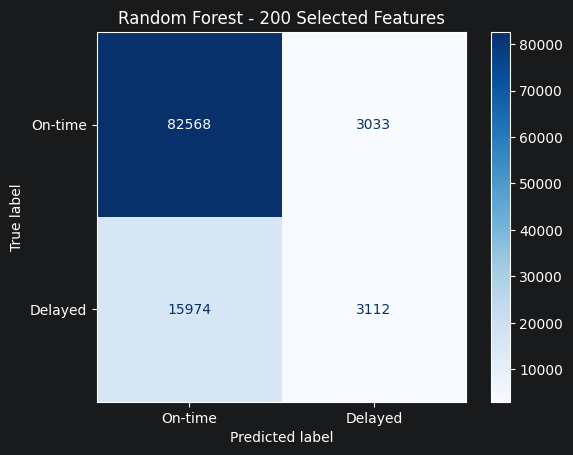

In [27]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# training Random Forest with 200 selected features
rf_reduced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reduced.fit(X_train_reduced, y_train)

# predicting using reduced test data
y_pred_reduced = rf_reduced.predict(X_test_reduced)

# evaluating performance
print("Random Forest - 200 Features")
print("--------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_reduced), 4))
print("Precision:", round(precision_score(y_test, y_pred_reduced), 4))
print("Recall:", round(recall_score(y_test, y_pred_reduced), 4))
print("F1-score:", round(f1_score(y_test, y_pred_reduced), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_reduced))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_reduced,
    display_labels=["On-time", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest - 200 Selected Features")
plt.show()


### 24. Results and Reflection — Feature Selection

After reducing the dataset from 699 to 200 features, I trained Random Forest again using the original class distribution.

The model achieved 81.84% accuracy, 50.64% precision, 16.31% recall, and a 24.67% F1-score for delayed flights.

Compared to the original Random Forest with 699 features, the results improved slightly across all four metrics. The model correctly identified 3,112 delayed flights instead of 2,938 and reduced the number of false delay predictions from 3,513 to 3,033.

This suggests that removing some of the less important features helped the model make slightly better predictions. However, the improvement in recall is still small, and the model continues to miss most delayed flights.

Looking back at Martijn's feedback, investigating the correlations and feature importance helped me better understand which features the model relies on. I also learned that reducing the number of features can improve performance, but it does not automatically solve the problem of predicting the minority class.

For now, I will keep the reduced dataset as a separate version so I can compare it with the original dataset without losing my previous work.

### 25. Random Forest with Feature Selection and Random Undersampling

After reducing the dataset to 200 features, I noticed a small improvement in the model's performance. However, the recall for delayed flights remained low at 16.31%.

Previously, Random Undersampling increased recall to 64.49%, but also produced many incorrect delay predictions.

For this final experiment, I will combine both approaches. I will apply Random Undersampling to the reduced training dataset and train Random Forest again.

The goal is to investigate whether using fewer features together with balanced training data can improve the model's ability to recognise delayed flights while reducing false predictions.

I will keep the test dataset unchanged, using the same 200 selected features, so I can compare the results with my previous models.

In [28]:

from imblearn.under_sampling import RandomUnderSampler
import numpy as np

# balancing the reduced training dataset
rus_reduced = RandomUnderSampler(random_state=42)

X_train_reduced_balanced, y_train_reduced_balanced = (
    rus_reduced.fit_resample(X_train_reduced, y_train)
)

# checking class distribution
unique, counts = np.unique(
    y_train_reduced_balanced,
    return_counts=True
)

print("Class distribution after balancing:")
for label, count in zip(unique, counts):
    print(f"Class {int(label)}: {count}")

print("\nBalanced training shape:",
      X_train_reduced_balanced.shape)

print("Test shape:", X_test_reduced.shape)


Class distribution after balancing:
Class 0: 76346
Class 1: 76346

Balanced training shape: (152692, 200)
Test shape: (104687, 200)


/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Users/marietasvetleva/PycharmProjects/Flight_Delay_Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(


### 26. Training and Evaluating the Final Model

Now that I have reduced the dataset to 200 features and balanced the training data using Random Undersampling, I will train another Random Forest model.

The training dataset contains an equal number of delayed and on-time flights. For testing, I will use the reduced V2 test dataset with the same 200 features, but keep its original class distribution.

This allows me to evaluate how well the model performs on data that reflects the original proportion of delayed flights.

I will compare precision, recall, F1-score, and the confusion matrix with my previous models to see whether combining feature selection and undersampling improves performance.

Random Forest - 200 Features + Random Undersampling
--------------------------------------------------
Accuracy: 0.6468
Precision: 0.2908
Recall: 0.6516
F1-score: 0.4022

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.65      0.75     85601
         1.0       0.29      0.65      0.40     19086

    accuracy                           0.65    104687
   macro avg       0.59      0.65      0.58    104687
weighted avg       0.78      0.65      0.69    104687



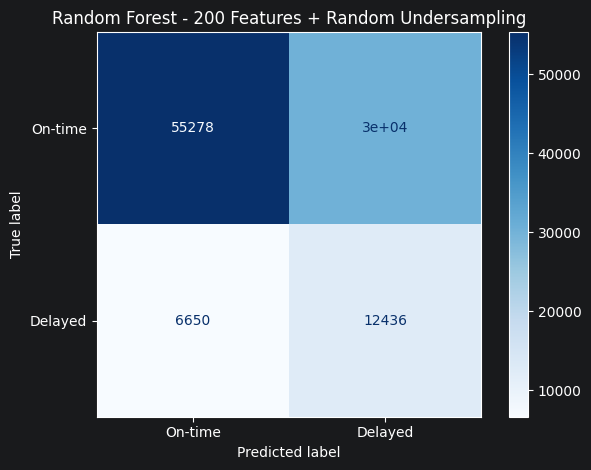

In [29]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# training Random Forest with 200 features and balanced training data
rf_reduced_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_reduced_balanced.fit(
    X_train_reduced_balanced,
    y_train_reduced_balanced
)

# predicting using the reduced V2 test dataset
y_pred_reduced_balanced = rf_reduced_balanced.predict(
    X_test_reduced
)

# evaluating the model
print("Random Forest - 200 Features + Random Undersampling")
print("--------------------------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred_reduced_balanced), 4))
print("Precision:", round(precision_score(y_test, y_pred_reduced_balanced), 4))
print("Recall:", round(recall_score(y_test, y_pred_reduced_balanced), 4))
print("F1-score:", round(f1_score(y_test, y_pred_reduced_balanced), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_reduced_balanced))

# confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_reduced_balanced,
    display_labels=["On-time", "Delayed"],
    cmap="Blues"
)

plt.title("Random Forest - 200 Features + Random Undersampling")
plt.tight_layout()
plt.show()


### 27. Final Model Comparison and Reflection

After applying Martijn's feedback, I tested different approaches to improve my flight delay prediction model. I compared the baseline Random Forest, Random Forest with class weights, Random Undersampling, feature selection, and finally a combination of feature selection and undersampling.

The original Random Forest achieved approximately 81% accuracy but only identified 15.39% of delayed flights. Adding class weights did not improve the results.

When I applied Random Undersampling, recall increased significantly to 64.49%. However, the model also produced many false delay predictions, which reduced its overall accuracy.

I then investigated the 699 features using correlation heatmaps and Random Forest feature importance. Based on this analysis, I selected the 200 most important features and trained the model again. This slightly improved the baseline model's performance.

Finally, I combined the 200 selected features with Random Undersampling. This model achieved 64.68% accuracy, 29.08% precision, 65.16% recall, and a 40.22% F1-score for delayed flights.

Compared to the previous undersampled model, the final model correctly identified 127 more delayed flights and produced approximately 1,500 fewer false delay predictions.

Overall, the combination of feature selection and undersampling achieved the highest recall and F1-score for delayed flights. However, the precision is still low, meaning that many flights predicted as delayed were actually on time.

From these experiments, I learned that accuracy alone does not give a complete picture of model performance, especially when the dataset is imbalanced. I also learned that having more features does not automatically lead to better predictions.

Although the final model performed better at detecting delays, I would not consider it ready for real-world use yet. For future improvements, I would investigate additional features, such as weather conditions, and test the model on data from different months to see whether it can generalise beyond January 2025.